# Aşama 2: Sayım ve ilk Monte Carlo

**Soru:** 4 aday kaynağın etrafındaki 1°'lik dairede, sadece arka plan olsaydı beklediğimizden fazla nötrino var mı?

**Yöntem:**
1. Her kaynağın etrafındaki olayları say (gözlenen).
2. Aynı yükselim (Dec) bandındaki olaylardan arka planda kaç olay beklediğimizi hesapla.
3. Olayların RA'larını rastgele dağıtıp sayımı binlerce kez tekrarla (Monte Carlo) → "şans eseri bu kadar olay görme olasılığı" = p-değeri.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

DATA = Path("../data")
RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)

cols = ['mjd', 'logE', 'angErr', 'ra', 'dec', 'az', 'zen']
dfs = []
for f in sorted(DATA.rglob("events/*.csv")):
    d = pd.read_csv(f, sep=r'\s+', comment='#', header=None, names=cols)
    d['season'] = f.stem.replace('_exp', '')
    dfs.append(d)
ev = pd.concat(dfs, ignore_index=True)
print(f"Toplam olay: {len(ev):,}")

Toplam olay: 1,134,450


## Kaynaklar

IceCube'un 10 yıllık katalog analizinde fazlalığı sürükleyen dört kaynak. Koordinatlar derece cinsinden (J2000).

**Daire yarıçapını (1°) veriye bakmadan, önceden sabitliyoruz.** Sonuca bakıp yarıçapı "en güzel çıkana" göre ayarlamak sahte anlamlılık üretir (p-hacking).

In [2]:
KAYNAKLAR = {
    'TXS 0506+056':    (77.358,  5.693),
    'NGC 1068':        (40.670, -0.013),
    'PKS 1424+240':    (216.752, 23.800),
    'GB6 J1542+6129':  (235.737, 61.499),
}
YARICAP = 1.0   # derece, önceden sabit

## Açısal uzaklık

Küre üzerinde iki nokta arasındaki açı:

$$\cos\psi = \sin\delta_1\sin\delta_2 + \cos\delta_1\cos\delta_2\cos(\alpha_1-\alpha_2)$$

`np.clip`: bilgisayar cos ψ'yi bazen 1.0000000002 gibi hesaplar, `arccos` buna NaN döndürür. Kırparak bunu önlüyoruz.

In [3]:
def acisal_uzaklik(ra1, dec1, ra2, dec2):
    ra1, dec1, ra2, dec2 = map(np.radians, (ra1, dec1, ra2, dec2))
    cos_psi = (np.sin(dec1) * np.sin(dec2)
               + np.cos(dec1) * np.cos(dec2) * np.cos(ra1 - ra2))
    return np.degrees(np.arccos(np.clip(cos_psi, -1, 1)))

# Testler: hepsi True olmalı
print(np.isclose(acisal_uzaklik(0, 0, 90, 0), 90))
print(np.isclose(acisal_uzaklik(0, 0, 0, 90), 90))
print(np.isclose(acisal_uzaklik(10, 20, 10, 20), 0))
print(np.isclose(acisal_uzaklik(0, 89, 180, 89), 2))

True
True
True
True


## Beklenen arka plan

Self-test 1'de gördük: olay yoğunluğu Dec'e bağlı, RA boyunca düzgün. O yüzden kaynağın Dec'i etrafında ince bir **bant** alıyoruz (±3°) ve şunu soruyoruz: bu banttaki olaylar bant boyunca düzgün yayılsaydı, 1°'lik daireye kaç tane düşerdi?

$$\text{beklenen} = N_{\text{bant}} \times \frac{\Omega_{\text{daire}}}{\Omega_{\text{bant}}}$$

- Dairenin katı açısı: $\Omega_{\text{daire}} = 2\pi(1-\cos r)$
- Bandın katı açısı: $\Omega_{\text{bant}} = 2\pi(\sin\delta_{\text{üst}} - \sin\delta_{\text{alt}})$

Yani alan oranı × banttaki olay sayısı. Kuzey ve güneydeki yoğunluk farkı otomatik olarak hesaba girmiş oluyor.

In [4]:
BANT = 3.0  # derece

def bant_olaylari(dec_kaynak):
    """Kaynağın Dec'i etrafındaki ±BANT bandındaki olaylar."""
    alt, ust = dec_kaynak - BANT, dec_kaynak + BANT
    maske = (ev['dec'] >= alt) & (ev['dec'] <= ust)
    return ev[maske], alt, ust

def beklenen_arka_plan(dec_kaynak, r=YARICAP):
    bant, alt, ust = bant_olaylari(dec_kaynak)
    omega_daire = 2 * np.pi * (1 - np.cos(np.radians(r)))
    omega_bant = 2 * np.pi * (np.sin(np.radians(ust)) - np.sin(np.radians(alt)))
    return len(bant) * omega_daire / omega_bant

ozet = []
for ad, (ra_k, dec_k) in KAYNAKLAR.items():
    psi = acisal_uzaklik(ev['ra'].values, ev['dec'].values, ra_k, dec_k)
    gozlenen = int(np.sum(psi < YARICAP))
    beklenen = beklenen_arka_plan(dec_k)
    ozet.append(dict(kaynak=ad, dec=dec_k, gozlenen=gozlenen,
                     beklenen=round(beklenen, 1), fazlalik=round(gozlenen - beklenen, 1)))

pd.DataFrame(ozet)

,kaynak,dec,gozlenen,beklenen,fazlalik
0,TXS 0506+056,5.693,160,149.0,11.0
1,NGC 1068,-0.013,193,137.0,56.0
2,PKS 1424+240,23.800,123,104.7,18.3
3,GB6 J1542+6129,61.499,82,72.4,9.6


## Monte Carlo: RA karıştırma

Fazlalık şans eseri mi? Bunu test etmek için **sadece arka planın olduğu sahte gökyüzleri** üretiyoruz:

1. Banttaki olayların Dec'ine dokunmadan RA'larını 0–360° arasında rastgele yeniden dağıt.
   - Dec'e dokunmuyoruz: dedektörün Dec'e bağlı davranışı korunuyor.
   - RA'yı karıştırıyoruz: Dünya döndüğü için RA'da her yön eşit, karıştırınca olası bir kaynak sinyali dağılıp yok oluyor.
2. Sahte gökyüzünde daireyi say.
3. Bunu 10.000 kez yap → "sadece arka plan olsaydı sayım nasıl dağılırdı?"
4. **p-değeri** = sahte gökyüzlerinin kaçında gözlenenden **en az o kadar** olay çıktı?

Sadece banttaki olayları karıştırmamız yeterli: Dec değişmediği için bant dışındaki olaylar asla daireye düşemez. Bu, hesabı yüzlerce kat hızlandırıyor.

In [5]:
rng = np.random.default_rng(seed=42)   # sabit tohum: sonuçlar tekrarlanabilir
N_DENEME = 10_000

def monte_carlo(ra_k, dec_k, n_deneme=N_DENEME, r=YARICAP):
    bant, _, _ = bant_olaylari(dec_k)
    dec_b = np.radians(bant['dec'].values)
    # Hız hilesi: Dec'ler hiç değişmediği için formüldeki sin/cos çarpımlarını
    # bir kere hesaplıyoruz. Ayrıca psi < r yerine cos(psi) > cos(r) kontrol ediyoruz,
    # böylece her denemede arccos hesaplamaya gerek kalmıyor.
    A = np.sin(dec_b) * np.sin(np.radians(dec_k))
    B = np.cos(dec_b) * np.cos(np.radians(dec_k))
    cos_r = np.cos(np.radians(r))
    sayimlar = np.empty(n_deneme, dtype=int)
    for i in range(n_deneme):
        ra_karisik = rng.uniform(0, 2 * np.pi, size=len(dec_b))
        cos_psi = A + B * np.cos(ra_karisik - np.radians(ra_k))
        sayimlar[i] = np.sum(cos_psi > cos_r)
    return sayimlar

sonuclar = {}
for satir in ozet:
    ra_k, dec_k = KAYNAKLAR[satir['kaynak']]
    sayimlar = monte_carlo(ra_k, dec_k)
    k = np.sum(sayimlar >= satir['gozlenen'])
    p = (k + 1) / (N_DENEME + 1)          # +1: p hiçbir zaman tam 0 çıkmasın
    sigma = stats.norm.isf(p)             # tek taraflı: p'yi Gauss sigmasına çevir
    p_poisson = stats.poisson.sf(satir['gozlenen'] - 1, satir['beklenen'])
    sonuclar[satir['kaynak']] = sayimlar
    satir.update(p_MC=p, sigma=round(sigma, 2), p_Poisson=p_poisson)

tablo = pd.DataFrame(ozet)
tablo.to_csv(RESULTS / 'asama2_sayim.csv', index=False)
tablo

,kaynak,dec,gozlenen,beklenen,fazlalik,p_MC,sigma,p_Poisson
0,TXS 0506+056,5.693,160,149.0,11.0,0.210779,0.80,0.193826
1,NGC 1068,-0.013,193,137.0,56.0,0.000200,3.54,0.000004
2,PKS 1424+240,23.800,123,104.7,18.3,0.049495,1.65,0.043692
3,GB6 J1542+6129,61.499,82,72.4,9.6,0.162784,0.98,0.142896


**Kontrol:** `p_MC` ve `p_Poisson` birbirine yakın çıkmalı. Rastgele, birbirinden bağımsız olaylar sayılırken sayım Poisson dağılımına uyar. Monte Carlo'nun bunu kendiliğinden yeniden üretmesi, simülasyonumuzun doğru çalıştığının kanıtı.

Peki Poisson formülü varken neden Monte Carlo? Çünkü Aşama 3'te sayım yerine likelihood test istatistiğine (TS) geçeceğiz ve TS'nin dağılımı için hazır bir formül yok. Monte Carlo ise her istatistik için çalışıyor.

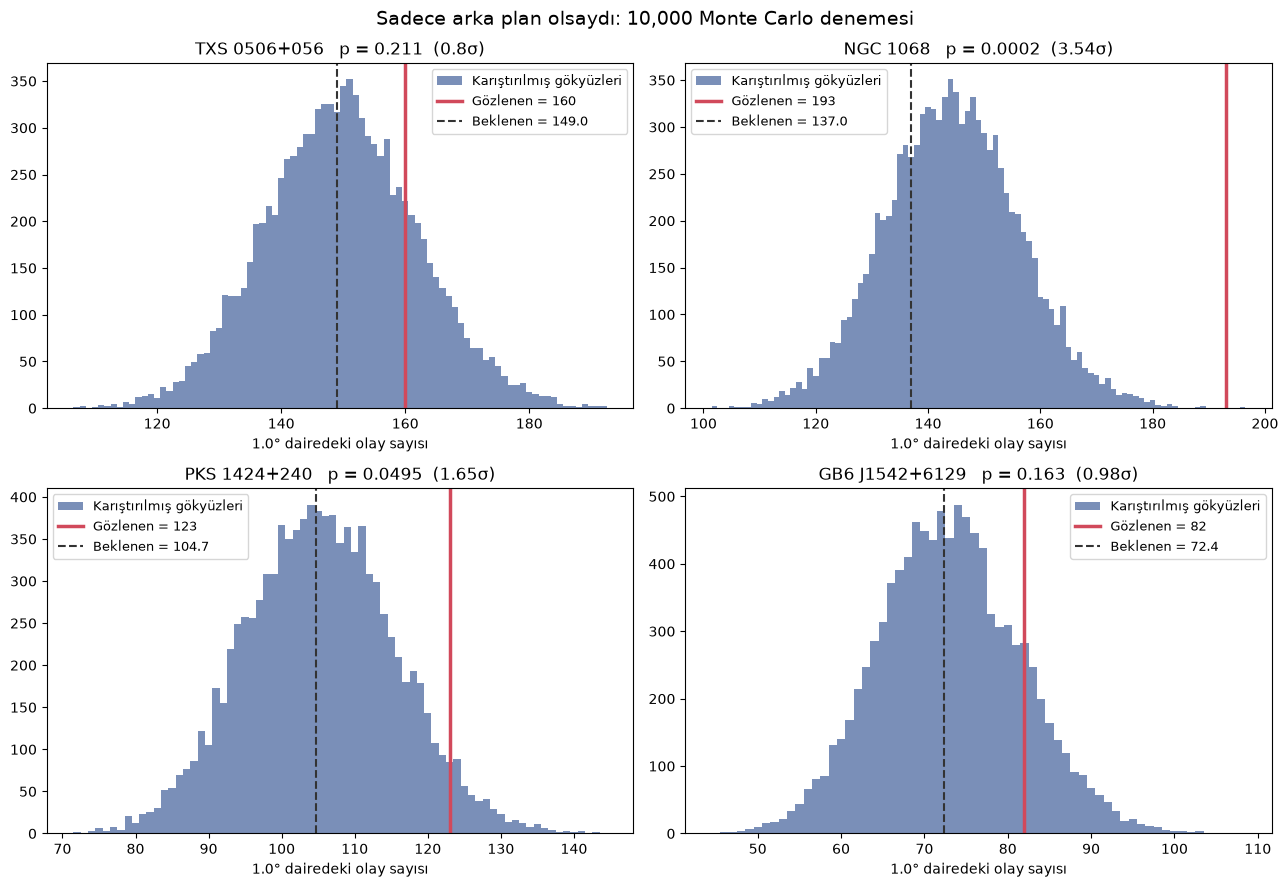

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
for ax, satir in zip(axs.flat, ozet):
    s = sonuclar[satir['kaynak']]
    kutular = np.arange(s.min(), max(s.max(), satir['gozlenen']) + 2) - 0.5
    ax.hist(s, bins=kutular, color='#7a8fb8', label='Karıştırılmış gökyüzleri')
    ax.axvline(satir['gozlenen'], color='#d1495b', lw=2.5,
               label=f"Gözlenen = {satir['gozlenen']}")
    ax.axvline(satir['beklenen'], color='#333', ls='--',
               label=f"Beklenen = {satir['beklenen']}")
    ax.set_title(f"{satir['kaynak']}   p = {satir['p_MC']:.3g}  ({satir['sigma']}σ)")
    ax.set_xlabel(f"{YARICAP}° dairedeki olay sayısı")
    ax.legend(fontsize=9)
fig.suptitle(f'Sadece arka plan olsaydı: {N_DENEME:,} Monte Carlo denemesi', fontsize=14)
plt.tight_layout()
plt.savefig(RESULTS / 'asama2_monte_carlo.png', dpi=150)
plt.show()

## Kaynağa yakından bakış: TXS 0506+056

Kaynağın etrafındaki 5°'lik bölgedeki olaylar. Her olayı kendi belirsizliği (angErr) kadar bir daireyle çiziyoruz: küçük daire = kesin yön, büyük daire = belirsiz yön.

**Dikkat:** Sayım yöntemi bu daireleri görmüyor; merkezdeki kesin bir olayla kenardaki belirsiz bir olayı eşit sayıyor. Aşama 3'teki likelihood bu bilgiyi kullanacak.

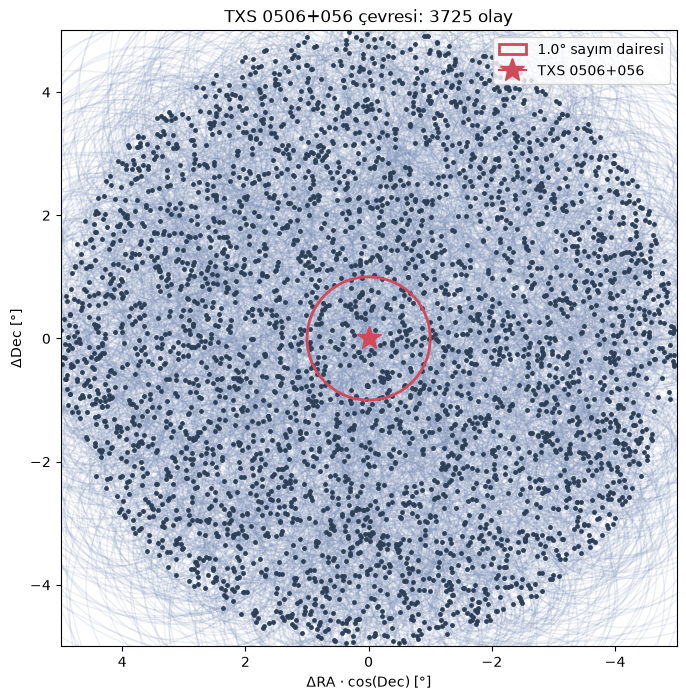

In [7]:
ra_k, dec_k = KAYNAKLAR['TXS 0506+056']
psi = acisal_uzaklik(ev['ra'].values, ev['dec'].values, ra_k, dec_k)
yakin = ev[psi < 5].copy()

fig, ax = plt.subplots(figsize=(8, 8))
# RA farkını cos(dec) ile çarpıyoruz: küre yüzeyinde gerçek açısal mesafe
x = (yakin['ra'] - ra_k) * np.cos(np.radians(dec_k))
y = yakin['dec'] - dec_k
for xi, yi, si in zip(x, y, yakin['angErr']):
    ax.add_patch(plt.Circle((xi, yi), si, fill=False, alpha=0.15, color='#7a8fb8'))
ax.scatter(x, y, s=6, color='#2e4057')
ax.add_patch(plt.Circle((0, 0), YARICAP, fill=False, color='#d1495b', lw=2,
                        label=f'{YARICAP}° sayım dairesi'))
ax.plot(0, 0, marker='*', color='#d1495b', ms=18, label='TXS 0506+056')
ax.set_xlim(5, -5); ax.set_ylim(-5, 5)    # RA sağdan sola artar
ax.set_aspect('equal')
ax.set_xlabel('ΔRA · cos(Dec) [°]'); ax.set_ylabel('ΔDec [°]')
ax.legend(loc='upper right')
ax.set_title(f'TXS 0506+056 çevresi: {len(yakin)} olay')
plt.savefig(RESULTS / 'asama2_txs_yakin.png', dpi=150, bbox_inches='tight')
plt.show()

## Sonuçları yorumlarken

- Sayım, kaba bir yöntem. Sigma değerlerinin IceCube makalesindekilerden **düşük** çıkması normal: onlar her olayın açısal belirsizliğini ve enerjisini de kullanıyor.
- 2 sigma altı sonuçlar "kanıt yok" demek, "kaynak yok" demek değil. Sinyal arka planda gömülü olabilir; daha güçlü bir test lazım.
- Bu da Aşama 3'ün motivasyonu: **unbinned likelihood**.